# Adaptive Dynamic RFM — Customer Behavior Analysis & Prediction

**Đề tài:** Phân tích và dự báo hành vi khách hàng sử dụng mô hình Dynamic RFM.

**Dataset chính:** Online Retail I (01/12/2010–09/12/2011). Notebook có thể đọc file Online Retail II, nhưng thí nghiệm chính lọc về khoảng thời gian Online Retail I để đảm bảo so sánh cùng dataset.

Mục tiêu: dự báo khách hàng đã biết có mua hàng trong **tháng kế tiếp** hay không.

Pipeline: Cleaning → Monthly snapshots → RFM → Temporal features → Temporal split → Baselines → Window selection → Model/threshold selection → Test → Ablation analysis.

> Test chỉ được sử dụng ở bước đánh giá cuối cùng. Không chọn window, model hoặc threshold dựa trên Test.

## 1. Import libraries & configuration

In [1]:
import warnings, os, glob
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
DATA_PATH = None  # Set file path if needed
WINDOWS = [30, 60, 90, 120, 180]

# Main experiment is Online Retail I period
DATA_START = "2010-12-01"
DATA_END = "2011-12-09"
SNAPSHOT_START = "2010-12"
SNAPSHOT_END = "2011-10"  # Predicts November 2011

# Temporal split: 7 train snapshots, 2 validation, 2 test
TRAIN_START, TRAIN_END = "2010-12", "2011-06"
VALID_START, VALID_END = "2011-07", "2011-08"
TEST_START, TEST_END = "2011-09", "2011-10"

pd.set_option("display.max_columns", 100)

## 2. Load Online Retail II
Upload the Excel file or set `DATA_PATH`. The loader reads both sheets when available.

In [3]:
def find_dataset():
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH

    # Prefer Online Retail I files for the main experiment.
    retail_i_patterns = (
        "**/online_retail.xlsx",
        "**/Online Retail.xlsx",
        "**/online_retail_1.xlsx",
        "**/Online Retail I.xlsx",
    )
    for pattern in retail_i_patterns:
        matches = glob.glob(pattern, recursive=True)
        if matches:
            return matches[0]

    # Compatible fallback: Online Retail II, which is filtered to Retail I dates later.
    retail_ii_patterns = (
        "**/*online*retail*ii*.xlsx",
        "**/*retail*ii*.xlsx",
    )
    for pattern in retail_ii_patterns:
        matches = glob.glob(pattern, recursive=True)
        if matches:
            return matches[0]

    candidates = glob.glob("**/*.xlsx", recursive=True)
    return candidates[0] if candidates else None

path = find_dataset()
if path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        path = next(iter(uploaded.keys()))
    except Exception:
        raise FileNotFoundError("Set DATA_PATH to the Online Retail I Excel file.")

print("Dataset:", path)

xls = pd.ExcelFile(path)
frames = []
for sheet in xls.sheet_names:
    tmp = pd.read_excel(path, sheet_name=sheet)
    frames.append(tmp)
df_raw = pd.concat(frames, ignore_index=True)
print("Raw shape:", df_raw.shape)
display(df_raw.head())

Saving Online Retail.xlsx to Online Retail.xlsx
Dataset: Online Retail.xlsx
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data Understanding

In [4]:
display(df_raw.info())
display(df_raw.isna().sum().sort_values(ascending=False))
display(df_raw.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

,0
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Basic Data Cleaning
Cleaning rules are based on record validity, not statistics learned from the entire dataset.

In [5]:
import pandas as pd
import numpy as np

# ============================================================
# 1. COPY RAW DATA
# ============================================================

df = df_raw.copy()

# Normalize column names
df.columns = [str(c).strip() for c in df.columns]

# ============================================================
# 2. NORMALIZE COLUMN NAMES
# Supports Online Retail I and other compatible datasets
# ============================================================

rename_map = {
    "InvoiceNo": "Invoice",
    "Invoice": "Invoice",

    "StockCode": "StockCode",

    "Description": "Description",

    "Quantity": "Quantity",

    "InvoiceDate": "InvoiceDate",

    "UnitPrice": "UnitPrice",
    "Price": "UnitPrice",

    "CustomerID": "CustomerID",
    "Customer ID": "CustomerID",

    "Country": "Country"
}

df = df.rename(columns=rename_map)

# ============================================================
# 3. VALIDATE REQUIRED COLUMNS
# ============================================================

required = [
    "Invoice",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

print("Column validation passed.")

# ============================================================
# 4. DATA TYPE CONVERSION
# ============================================================

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

df["CustomerID"] = pd.to_numeric(
    df["CustomerID"],
    errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"],
    errors="coerce"
)

# ============================================================
# 5. REMOVE MISSING / INVALID VALUES
# ============================================================

df = df.dropna(
    subset=[
        "Invoice",
        "InvoiceDate",
        "CustomerID",
        "Quantity",
        "UnitPrice"
    ]
)

# CustomerID must be integer
df["CustomerID"] = df["CustomerID"].astype("int64")

# Normalize Invoice ID
df["Invoice"] = (
    df["Invoice"]
    .astype(str)
    .str.strip()
)

# ============================================================
# 6. REMOVE CANCELLED INVOICES
# ============================================================

df = df[
    ~df["Invoice"]
    .str.upper()
    .str.startswith("C", na=False)
]

# ============================================================
# 7. REMOVE INVALID TRANSACTIONS
# ============================================================

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

# ============================================================
# 8. REMOVE EXACT DUPLICATES
# ============================================================

df = df.drop_duplicates()

# ============================================================
# 9. FEATURE ENGINEERING
# ============================================================

df["TotalAmount"] = (
    df["Quantity"] *
    df["UnitPrice"]
)

# ============================================================
# 10. SORT TRANSACTIONS BY TIME
# ============================================================

df = (
    df.sort_values("InvoiceDate")
      .reset_index(drop=True)
)

# Restrict the main experiment to Online Retail I date coverage.
# If Online Retail II is uploaded, this filters it to the same period.
df = df[
    (df["InvoiceDate"] >= pd.Timestamp(DATA_START)) &
    (df["InvoiceDate"] < pd.Timestamp(DATA_END) + pd.Timedelta(days=1))
].copy().reset_index(drop=True)

# ============================================================
# 11. DATA QUALITY REPORT
# ============================================================

print("=" * 60)
print("DATA CLEANING REPORT")
print("=" * 60)

print(f"Cleaned shape       : {df.shape}")
print(f"Total transactions  : {len(df):,}")
print(f"Unique customers    : {df['CustomerID'].nunique():,}")
print(f"Unique invoices     : {df['Invoice'].nunique():,}")
print(f"Unique products     : {df['StockCode'].nunique():,}" if "StockCode" in df.columns else "StockCode not available")
print(f"Date range          : {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
print(f"Total revenue       : {df['TotalAmount'].sum():,.2f}")

print("=" * 60)

# ============================================================
# 12. CHECK DATA QUALITY
# ============================================================

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nQuantity statistics:")
display(df["Quantity"].describe())

print("\nUnitPrice statistics:")
display(df["UnitPrice"].describe())

print("\nTotalAmount statistics:")
display(df["TotalAmount"].describe())

# ============================================================
# 13. DISPLAY CLEANED DATA
# ============================================================

display(df.head())

print("\nData cleaning completed successfully.")

Column validation passed.
DATA CLEANING REPORT
Cleaned shape       : (392692, 9)
Total transactions  : 392,692
Unique customers    : 4,338
Unique invoices     : 18,532
Unique products     : 3,665
Date range          : 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total revenue       : 8,887,208.89

Missing values:


,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
TotalAmount,0



Duplicate rows:
0

Quantity statistics:


,Quantity
count,392692.000000
mean,13.119702
std,180.492832
min,1.000000
25%,2.000000
50%,6.000000
75%,12.000000
max,80995.000000



UnitPrice statistics:


,UnitPrice
count,392692.000000
mean,3.125914
std,22.241836
min,0.001000
25%,1.250000
50%,1.950000
75%,3.750000
max,8142.750000



TotalAmount statistics:


,TotalAmount
count,392692.000000
mean,22.631500
std,311.099224
min,0.001000
25%,4.950000
50%,12.450000
75%,19.800000
max,168469.600000


,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34



Data cleaning completed successfully.


## 5. Explore transaction volume

,Transactions,Customers,Revenue
InvoiceDate,,,
2010-12-01,1400,885,570422.730
2011-01-01,987,741,568101.310
2011-02-01,997,758,446084.920
2011-03-01,1321,974,594081.760
2011-04-01,1149,856,468374.331
2011-05-01,1555,1056,677355.150
2011-06-01,1393,991,660046.050
2011-07-01,1331,949,598962.901
2011-08-01,1280,935,644051.040


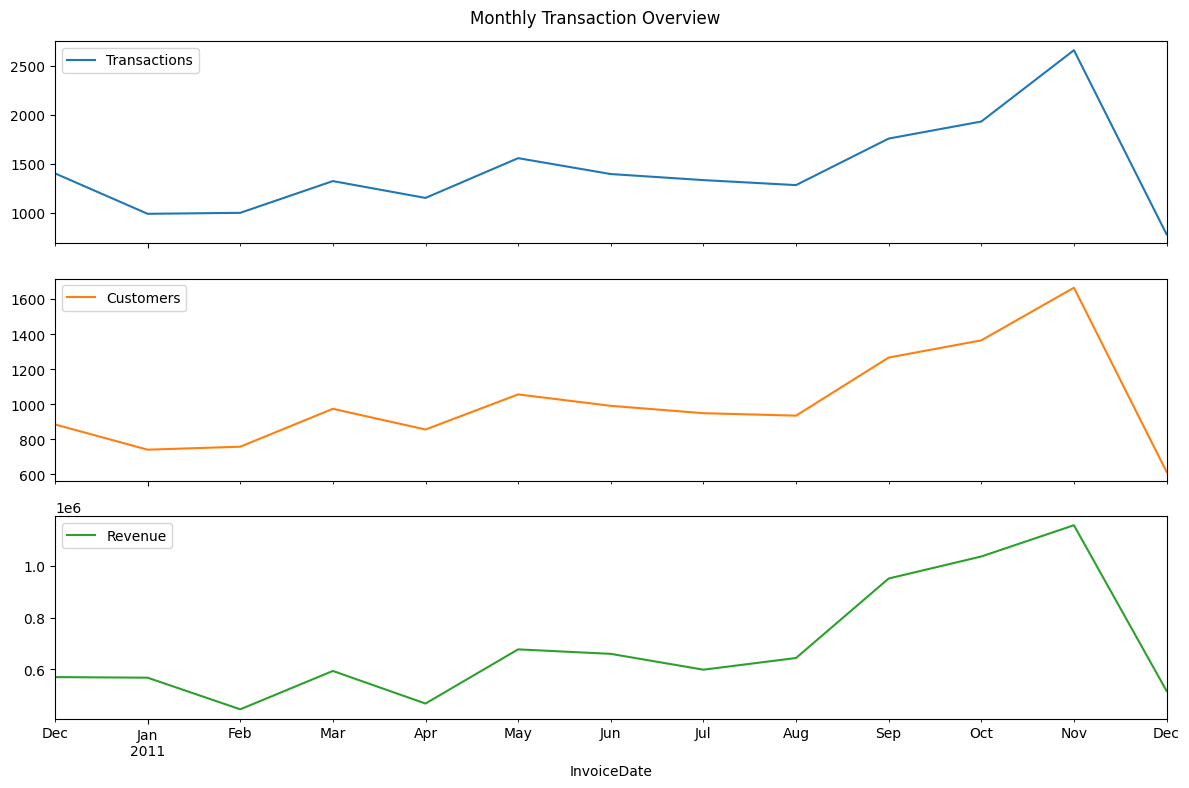

In [6]:
monthly_tx = df.set_index("InvoiceDate").resample("MS").agg(
    Transactions=("Invoice", "nunique"),
    Customers=("CustomerID", "nunique"),
    Revenue=("TotalAmount", "sum")
)
display(monthly_tx)
monthly_tx[["Transactions", "Customers", "Revenue"]].plot(
    subplots=True, figsize=(12, 8), title="Monthly Transaction Overview"
)
plt.tight_layout()
plt.show()


## 6. Temporal split & target definition

Each snapshot at month-end uses transactions up to that cutoff. The target is whether a previously known customer purchases during the **following calendar month**.

- Train snapshots: 2010-01 to 2010-12
- Validation snapshots: 2011-01 to 2011-06
- Test snapshots: 2011-07 to 2011-10

The October 2011 snapshot predicts November 2011, avoiding the incomplete December period in this dataset.


In [7]:
def month_periods(start=SNAPSHOT_START, end=SNAPSHOT_END):
    return pd.period_range(start=start, end=end, freq="M")

snapshot_periods = month_periods()
print(snapshot_periods)


PeriodIndex(['2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05',
             '2011-06', '2011-07', '2011-08', '2011-09', '2011-10'],
            dtype='period[M]')


## 7. Snapshot generator: RFM + next-month purchase label

In [8]:
import pandas as pd
import numpy as np

# ============================================================
# 1. SNAPSHOT GENERATION
# ============================================================

def make_snapshot(data, period, window_days=None):

    period = pd.Period(period, freq="M")

    # Snapshot cutoff: beginning of next month
    cutoff = (period + 1).start_time

    # Future prediction period: next month
    next_period = period + 1

    next_start = next_period.start_time
    next_end = (next_period + 1).start_time

    # ========================================================
    # 2. HISTORICAL DATA
    # ========================================================

    hist = data[
        data["InvoiceDate"] < cutoff
    ].copy()

    # ========================================================
    # 3. FUTURE DATA (TARGET)
    # ========================================================

    future = data[
        (data["InvoiceDate"] >= next_start) &
        (data["InvoiceDate"] < next_end)
    ].copy()

    # ========================================================
    # 4. VALIDATE HISTORICAL DATA
    # ========================================================

    if hist.empty:

        print(f"Warning: No historical data before {period}")

        return pd.DataFrame(columns=[
            "CustomerID",
            "R",
            "F",
            "M",
            "Q",
            "snapshot",
            "snapshot_period",
            "window",
            "target_purchase_next_month"
        ])

    # Customers known before snapshot
    customers = hist["CustomerID"].unique()

    # ========================================================
    # 5. RECENCY
    # ========================================================

    last_purchase = (
        hist.groupby("CustomerID")["InvoiceDate"]
        .max()
    )

    recency = (
        (cutoff - last_purchase)
        .dt.days
        .rename("R")
    )

    # ========================================================
    # 6. SELECT RFM WINDOW
    # ========================================================

    if window_days is None:

        selected = hist.copy()
        suffix = "lifetime"

    else:

        start_date = cutoff - pd.Timedelta(
            days=window_days
        )

        selected = hist[
            hist["InvoiceDate"] >= start_date
        ].copy()

        suffix = f"{window_days}d"

    # ========================================================
    # 7. FREQUENCY / MONETARY / QUANTITY
    # ========================================================

    agg = (
        selected.groupby("CustomerID")
        .agg(
            F=("Invoice", "nunique"),
            M=("TotalAmount", "sum"),
            Q=("Quantity", "sum")
        )
    )

    # ========================================================
    # 8. BUILD SNAPSHOT
    # ========================================================

    out = pd.DataFrame(
        index=pd.Index(
            customers,
            name="CustomerID"
        )
    )

    out = out.join(recency)
    out = out.join(agg)

    out[["F", "M", "Q"]] = (
        out[["F", "M", "Q"]]
        .fillna(0)
    )

    out["snapshot"] = period.to_timestamp("M")

    out["snapshot_period"] = str(period)

    out["window"] = suffix

    # ========================================================
    # 9. FUTURE PURCHASE TARGET
    # ========================================================

    future_customers = set(
        future["CustomerID"].unique()
    )

    out["target_purchase_next_month"] = (
        out.index
        .isin(future_customers)
        .astype(int)
    )

    # ========================================================
    # 10. FINALIZE
    # ========================================================

    out = out.reset_index()

    return out


# ============================================================
# 11. SANITY CHECK
# ============================================================

print("Dataset date range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

# Use a valid snapshot period
sample = make_snapshot(
    data=df,
    period="2011-06",
    window_days=90
)

display(sample.head())

print("=" * 50)
print("SNAPSHOT REPORT")
print("=" * 50)

print("Snapshot period:", "2011-06")
print("Window:", "90 days")
print("Snapshot rows:", len(sample))

if not sample.empty:

    print(
        "Positive target rate:",
        sample["target_purchase_next_month"].mean()
    )

    print(
        "Customers purchasing next month:",
        sample["target_purchase_next_month"].sum()
    )

    print(
        "Customers not purchasing next month:",
        (sample["target_purchase_next_month"] == 0).sum()
    )

else:

    print("Snapshot is empty. Check dataset date range.")

Dataset date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


,CustomerID,R,F,M,Q,snapshot,snapshot_period,window,target_purchase_next_month
0,17850,210,0.0,0.00,0.0,2011-06-30,2011-06,90d,0
1,13047,11,2.0,981.40,350.0,2011-06-30,2011-06,90d,0
2,12583,9,3.0,1039.44,1373.0,2011-06-30,2011-06,90d,1
3,13748,70,2.0,376.85,143.0,2011-06-30,2011-06,90d,0
4,15100,171,0.0,0.00,0.0,2011-06-30,2011-06,90d,0


SNAPSHOT REPORT
Snapshot period: 2011-06
Window: 90 days
Snapshot rows: 2960
Positive target rate: 0.2570945945945946
Customers purchasing next month: 761
Customers not purchasing next month: 2199


## 8. Build datasets for all candidate windows

In [9]:
snapshot_cache = {}
for window in WINDOWS:
    parts = [make_snapshot(df, p, window) for p in snapshot_periods]
    data_window = pd.concat(parts, ignore_index=True)
    snapshot_cache[window] = data_window
    print(window, "days:", data_window.shape, "positive rate:", round(data_window["target_purchase_next_month"].mean(), 4))

# Lifetime/static RFM baseline
static_parts = [make_snapshot(df, p, None) for p in snapshot_periods]
static_data = pd.concat(static_parts, ignore_index=True)


30 days: (28170, 9) positive rate: 0.289
60 days: (28170, 9) positive rate: 0.289
90 days: (28170, 9) positive rate: 0.289
120 days: (28170, 9) positive rate: 0.289
180 days: (28170, 9) positive rate: 0.289


## 9. Temporal feature engineering
Lag features are calculated only from earlier snapshots for the same customer.

In [10]:
BASE_FEATURES = ["R", "F", "M", "Q"]

def add_temporal_features(data):
    x = data.sort_values(["CustomerID", "snapshot"]).copy()
    for col in BASE_FEATURES:
        x[f"{col}_lag1"] = x.groupby("CustomerID")[col].shift(1)
        x[f"{col}_lag2"] = x.groupby("CustomerID")[col].shift(2)
        x[f"{col}_delta1"] = x[col] - x[f"{col}_lag1"]
    x["F_trend_3"] = x.groupby("CustomerID")["F"].transform(
        lambda s: s - s.shift(2)
    )
    x["M_trend_3"] = x.groupby("CustomerID")["M"].transform(
        lambda s: s - s.shift(2)
    )
    # Missing historical snapshots mean "no previous snapshot"; imputation happens in model pipeline.
    return x

feature_cache = {w: add_temporal_features(data) for w, data in snapshot_cache.items()}
static_features = add_temporal_features(static_data)
display(feature_cache[90].head())


,CustomerID,R,F,M,Q,snapshot,snapshot_period,window,target_purchase_next_month,R_lag1,R_lag2,R_delta1,F_lag1,F_lag2,F_delta1,M_lag1,M_lag2,M_delta1,Q_lag1,Q_lag2,Q_delta1,F_trend_3,M_trend_3
1989,12346,13,1.0,77183.6,74215.0,2011-01-31,2011-01,90d,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3291,12346,41,1.0,77183.6,74215.0,2011-02-28,2011-02,90d,0,13.0,NaN,28.0,1.0,NaN,0.0,77183.6,NaN,0.0,74215.0,NaN,0.0,NaN,NaN
4973,12346,72,1.0,77183.6,74215.0,2011-03-31,2011-03,90d,0,41.0,13.0,31.0,1.0,1.0,0.0,77183.6,77183.6,0.0,74215.0,74215.0,0.0,0.0,0.0
7107,12346,102,0.0,0.0,0.0,2011-04-30,2011-04,90d,0,72.0,41.0,30.0,1.0,1.0,-1.0,77183.6,77183.6,-77183.6,74215.0,74215.0,-74215.0,-1.0,-77183.6
9541,12346,133,0.0,0.0,0.0,2011-05-31,2011-05,90d,0,102.0,72.0,31.0,0.0,1.0,0.0,0.0,77183.6,0.0,0.0,74215.0,0.0,-1.0,-77183.6


## 10. Temporal Train / Validation / Test Split

- Train snapshots: 2010-12 → 2011-06 (7 snapshots)
- Validation snapshots: 2011-07 → 2011-08 (2 snapshots)
- Test snapshots: 2011-09 → 2011-10 (2 snapshots)

Mỗi snapshot tháng *t* dùng dữ liệu đến hết tháng *t* và dự báo mua hàng trong tháng *t+1*. Các tháng target giữa Train, Validation và Test không chồng lấn.

In [11]:
def split_temporal(data):
    p = data["snapshot_period"].astype(str)
    train = data[(p >= TRAIN_START) & (p <= TRAIN_END)].copy()
    valid = data[(p >= VALID_START) & (p <= VALID_END)].copy()
    test = data[(p >= TEST_START) & (p <= TEST_END)].copy()
    return train, valid, test

for w, data in feature_cache.items():
    tr, va, te = split_temporal(data)
    print(f"{w}d | train={tr.shape} | validation={va.shape} | test={te.shape}")

train_static, valid_static, test_static = split_temporal(static_features)

# Fail early if a split is empty or has only one target class.
for label, split in [("Train", train_static), ("Validation", valid_static), ("Test", test_static)]:
    if split.empty:
        raise ValueError(f"{label} split is empty. Check dataset date range and snapshot settings.")
    print(label, "positive rate:", round(split["target_purchase_next_month"].mean(), 4))

30d | train=(14115, 23) | validation=(6465, 23) | test=(7590, 23)
60d | train=(14115, 23) | validation=(6465, 23) | test=(7590, 23)
90d | train=(14115, 23) | validation=(6465, 23) | test=(7590, 23)
120d | train=(14115, 23) | validation=(6465, 23) | test=(7590, 23)
180d | train=(14115, 23) | validation=(6465, 23) | test=(7590, 23)
Train positive rate: 0.2878
Validation positive rate: 0.2681
Test positive rate: 0.3092


## 11. Feature groups, baselines & metrics

- **Static RFM:** Lifetime RFM only.
- **Fixed Rolling RFM:** RFM within a fixed window, no temporal lags.
- **Dynamic RFM:** Rolling RFM + historical lag/delta features.
- **Adaptive Dynamic RFM:** window selected on Validation using Dynamic features.

All models use the same target and temporal split. Preprocessing is fitted inside each model pipeline using Train only.

In [12]:
TARGET = "target_purchase_next_month"
BASE_FEATURES = ["R", "F", "M", "Q"]
TEMPORAL_FEATURES = (
    BASE_FEATURES +
    [f"{c}_lag1" for c in BASE_FEATURES] +
    [f"{c}_lag2" for c in BASE_FEATURES] +
    [f"{c}_delta1" for c in BASE_FEATURES] +
    ["F_trend_3", "M_trend_3"]
)

def get_xy(data, features):
    X = data[features].replace([np.inf, -np.inf], np.nan)
    y = data[TARGET].astype(int)
    return X, y

def make_lr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ])

def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])

def score_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, prob) if len(np.unique(y_true)) > 1 else np.nan,
        "PR_AUC": average_precision_score(y_true, prob) if len(np.unique(y_true)) > 1 else np.nan
    }

def choose_threshold(y_true, prob):
    thresholds = np.arange(0.10, 0.91, 0.01)
    rows = [(t, f1_score(y_true, (prob >= t).astype(int), zero_division=0)) for t in thresholds]
    return max(rows, key=lambda x: x[1])[0]

print("Feature groups ready.")
print("Train class distribution:")
display(train_static[TARGET].value_counts(normalize=True).rename("proportion"))

Feature groups ready.
Train class distribution:


,proportion
target_purchase_next_month,
0,0.712221
1,0.287779


## 12. Baseline & window selection on Validation

Window selection is conducted using Dynamic RFM features. A fixed 90-day window is included as a reference. Static RFM uses Lifetime values without lag features. Validation is used for selection only.

In [13]:
# Majority-class baseline
train_s, valid_s, test_s = split_temporal(static_features)
Xtr_static, ytr_static = get_xy(train_s, BASE_FEATURES)
Xva_static, yva_static = get_xy(valid_s, BASE_FEATURES)
Xte_static, yte_static = get_xy(test_s, BASE_FEATURES)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(Xtr_static, ytr_static)
dummy_prob = dummy.predict_proba(Xva_static)[:, 1]

# Select rolling window using RF + temporal features on Validation
window_validation_rows = []
window_models = {}
for w in WINDOWS:
    tr, va, _ = split_temporal(feature_cache[w])
    Xtr, ytr = get_xy(tr, TEMPORAL_FEATURES)
    Xva, yva = get_xy(va, TEMPORAL_FEATURES)
    model = make_rf()
    model.fit(Xtr, ytr)
    p = model.predict_proba(Xva)[:, 1]
    threshold = choose_threshold(yva, p)
    row = {"Window_days": w, **score_metrics(yva, p, threshold), "Threshold": threshold}
    window_validation_rows.append(row)
    window_models[w] = model

window_validation = pd.DataFrame(window_validation_rows).sort_values("F1", ascending=False)
display(window_validation)
best_window = int(window_validation.iloc[0]["Window_days"])
print("Selected Adaptive window:", best_window, "days")

# Baseline validation table, using RF consistently
baseline_validation_rows = []
for name, data, features in [("Static/Lifetime RFM", static_features, BASE_FEATURES),
                              ("Fixed Rolling 90d", feature_cache[90], BASE_FEATURES),
                              ("Dynamic RFM 90d + Temporal", feature_cache[90], TEMPORAL_FEATURES),
                              (f"Adaptive Dynamic RFM {best_window}d", feature_cache[best_window], TEMPORAL_FEATURES)]:
    tr, va, _ = split_temporal(data)
    Xtr, ytr = get_xy(tr, features)
    Xva, yva = get_xy(va, features)
    model = make_rf()
    model.fit(Xtr, ytr)
    p = model.predict_proba(Xva)[:, 1]
    threshold = choose_threshold(yva, p)
    baseline_validation_rows.append({"Method": name, **score_metrics(yva, p, threshold), "Threshold": threshold})

baseline_validation = pd.DataFrame(baseline_validation_rows).sort_values("F1", ascending=False)
display(baseline_validation)

,Window_days,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
4,180,0.715700,0.475547,0.589152,0.526289,0.732022,0.565033,0.36
3,120,0.696984,0.451751,0.610502,0.519264,0.726047,0.559318,0.34
2,90,0.665584,0.420878,0.658396,0.513501,0.723286,0.557834,0.30
1,60,0.688012,0.440135,0.602424,0.508648,0.714718,0.545595,0.34
0,30,0.676411,0.427240,0.608194,0.501905,0.708101,0.532253,0.34


Selected Adaptive window: 180 days


,Method,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
3,Adaptive Dynamic RFM 180d,0.715700,0.475547,0.589152,0.526289,0.732022,0.565033,0.36
0,Static/Lifetime RFM,0.712142,0.470452,0.587998,0.522698,0.724056,0.555221,0.42
2,Dynamic RFM 90d + Temporal,0.665584,0.420878,0.658396,0.513501,0.723286,0.557834,0.30
1,Fixed Rolling 90d,0.662490,0.409876,0.589152,0.483428,0.697823,0.523448,0.34


## 13. Model selection for selected Adaptive Window

Compare Logistic Regression and Random Forest on the selected window. Model and threshold are selected using Validation only.

In [14]:
selected_data = feature_cache[best_window]
train_selected, valid_selected, test_selected = split_temporal(selected_data)
X_train, y_train = get_xy(train_selected, TEMPORAL_FEATURES)
X_valid, y_valid = get_xy(valid_selected, TEMPORAL_FEATURES)
X_test, y_test = get_xy(test_selected, TEMPORAL_FEATURES)

models = {"Logistic Regression": make_lr(), "Random Forest": make_rf()}
model_rows = []
fit_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_valid)[:, 1]
    threshold = choose_threshold(y_valid, prob)
    model_rows.append({"Model": name, **score_metrics(y_valid, prob, threshold), "Threshold": threshold})
    fit_models[name] = (model, threshold)

model_validation = pd.DataFrame(model_rows).sort_values("F1", ascending=False)
display(model_validation)
best_model_name = model_validation.iloc[0]["Model"]
best_model, best_threshold = fit_models[best_model_name]
print("Selected model:", best_model_name)
print("Selected threshold:", round(float(best_threshold), 3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
0,Logistic Regression,0.70379,0.461441,0.628390,0.532128,0.731365,0.568898,0.44
1,Random Forest,0.71570,0.475547,0.589152,0.526289,0.732022,0.565033,0.36


Selected model: Logistic Regression
Selected threshold: 0.44


## 14. Final Test evaluation

Evaluate the selected model/window/threshold once on Test. Do not alter selections based on these results.

In [18]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_metrics = score_metrics(y_test, test_prob, best_threshold)
print("Final Test Metrics")
display(pd.DataFrame([test_metrics], index=[best_model_name]))

test_pred = (test_prob >= best_threshold).astype(int)
print(classification_report(y_test, test_pred, zero_division=0))
cm = confusion_matrix(y_test, test_pred)
display(pd.DataFrame(cm, index=["Actual No Purchase", "Actual Purchase"],
                     columns=["Predicted No Purchase", "Predicted Purchase"]))

Final Test Metrics


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.702372,0.517107,0.566681,0.54076,0.713465,0.57999


              precision    recall  f1-score   support

           0       0.80      0.76      0.78      5243
           1       0.52      0.57      0.54      2347

    accuracy                           0.70      7590
   macro avg       0.66      0.66      0.66      7590
weighted avg       0.71      0.70      0.71      7590



,Predicted No Purchase,Predicted Purchase
Actual No Purchase,4001,1242
Actual Purchase,1017,1330


## 15. Test comparison: ablation & method comparison

Compare the methods on the same Test snapshots and with RF to isolate the feature/window contribution. Thresholds are selected separately on Validation for each method.

In [15]:
experiment_specs = [
    ("E1 Static Lifetime RFM", static_features, BASE_FEATURES),
    ("E2 Fixed Rolling 90d", feature_cache[90], BASE_FEATURES),
    ("E3 Dynamic RFM 90d + Temporal", feature_cache[90], TEMPORAL_FEATURES),
    (f"E4 Adaptive Dynamic RFM {best_window}d + Temporal", feature_cache[best_window], TEMPORAL_FEATURES),
]

test_rows = []
experiment_artifacts = {}
for name, data, features in experiment_specs:
    tr, va, te = split_temporal(data)
    Xtr, ytr = get_xy(tr, features)
    Xva, yva = get_xy(va, features)
    Xte, yte = get_xy(te, features)
    model = make_rf()
    model.fit(Xtr, ytr)
    val_prob = model.predict_proba(Xva)[:, 1]
    threshold = choose_threshold(yva, val_prob)
    test_prob = model.predict_proba(Xte)[:, 1]
    test_rows.append({"Method": name, **score_metrics(yte, test_prob, threshold), "Threshold": threshold})
    experiment_artifacts[name] = {"model": model, "threshold": threshold, "test_prob": test_prob, "y_test": yte}

test_comparison = pd.DataFrame(test_rows).sort_values("F1", ascending=False)
display(test_comparison)

# Calculate absolute improvement of proposed method vs static baseline
static_row = test_comparison[test_comparison["Method"] == "E1 Static Lifetime RFM"].iloc[0]
proposed_row = test_comparison[test_comparison["Method"].str.startswith("E4")].iloc[0]
print("F1 improvement vs Static:", round(proposed_row["F1"] - static_row["F1"], 4))
print("PR-AUC improvement vs Static:", round(proposed_row["PR_AUC"] - static_row["PR_AUC"], 4))

,Method,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
0,E1 Static Lifetime RFM,0.674704,0.478168,0.569237,0.519743,0.701267,0.563702,0.42
3,E4 Adaptive Dynamic RFM 180d + Temporal,0.697497,0.510481,0.529186,0.519665,0.709342,0.571337,0.36
2,E3 Dynamic RFM 90d + Temporal,0.644664,0.445854,0.613975,0.516580,0.693643,0.564534,0.30
1,E2 Fixed Rolling 90d,0.642688,0.437177,0.541116,0.483625,0.672027,0.533715,0.34


F1 improvement vs Static: -0.0001
PR-AUC improvement vs Static: 0.0076


## 16. Visualization

Visualize F1, ROC-AUC and PR-AUC for methods evaluated on the same Test set.

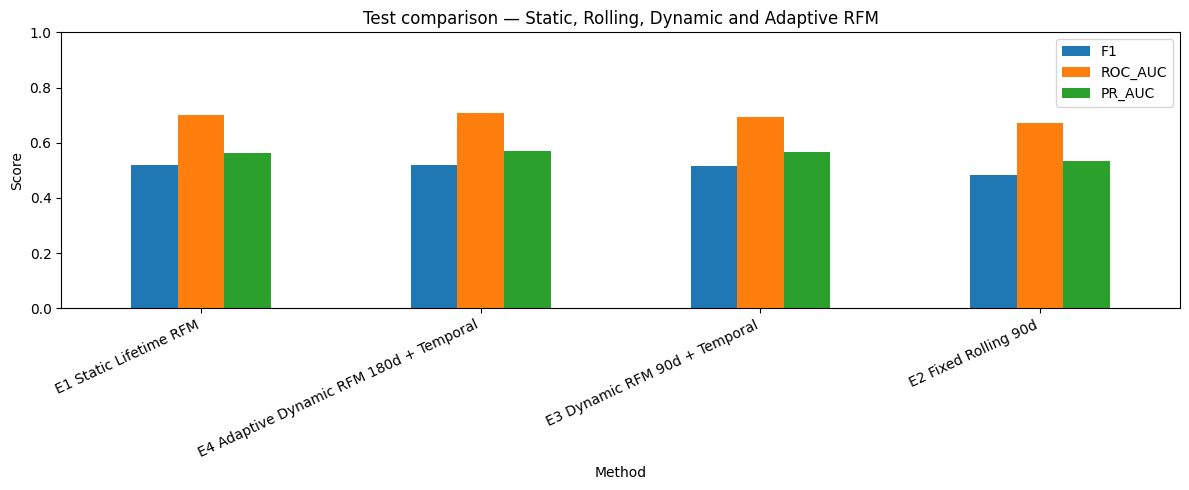

In [16]:
plot_df = test_comparison.set_index("Method")[["F1", "ROC_AUC", "PR_AUC"]]
plot_df.plot(kind="bar", figsize=(12, 5))
plt.title("Test comparison — Static, Rolling, Dynamic and Adaptive RFM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 17. Customer-level prediction example

Show customers in the latest test snapshot with predicted probability. This is an illustrative output, not a new evaluation.

In [17]:
latest_test_snapshot = test_selected["snapshot"].max()
latest = test_selected[test_selected["snapshot"] == latest_test_snapshot].copy()
latest_X = latest[TEMPORAL_FEATURES].replace([np.inf, -np.inf], np.nan)
latest["purchase_probability"] = best_model.predict_proba(latest_X)[:, 1]
latest["predicted_purchase"] = (latest["purchase_probability"] >= best_threshold).astype(int)
display(latest.sort_values("purchase_probability", ascending=False).head(20))

,CustomerID,R,F,M,Q,snapshot,snapshot_period,window,target_purchase_next_month,R_lag1,R_lag2,R_delta1,F_lag1,F_lag2,F_delta1,M_lag1,M_lag2,M_delta1,Q_lag1,Q_lag2,Q_delta1,F_trend_3,M_trend_3,purchase_probability,predicted_purchase
24261,14911,0,110.0,83509.21,49796.0,2011-10-31,2011-10,180d,1,0.0,5.0,0.0,95.0,81.0,15.0,69437.16,58856.92,14072.05,38972.0,31964.0,10824.0,29.0,24652.29,1.000000,1
24242,12748,5,92.0,14383.75,11628.0,2011-10-31,2011-10,180d,1,0.0,1.0,5.0,81.0,83.0,11.0,13226.62,8355.34,1157.13,9047.0,5433.0,2581.0,9.0,6028.41,1.000000,1
24617,18102,10,42.0,186364.31,42253.0,2011-10-31,2011-10,180d,1,2.0,26.0,8.0,32.0,19.0,10.0,134880.00,90771.14,51484.31,30695.0,20470.0,11558.0,23.0,95593.17,1.000000,1
24265,17841,0,66.0,22022.83,12977.0,2011-10-31,2011-10,180d,1,2.0,3.0,-2.0,57.0,55.0,9.0,18940.94,16603.99,3081.89,10821.0,9577.0,2156.0,11.0,5418.84,1.000000,1
25042,14646,4,41.0,160797.61,111456.0,2011-10-31,2011-10,180d,1,8.0,5.0,-4.0,32.0,30.0,9.0,123778.22,118489.92,37019.39,86482.0,83443.0,24974.0,11.0,42307.69,1.000000,1
24570,17450,0,25.0,127224.36,46196.0,2011-10-31,2011-10,180d,1,0.0,8.0,0.0,25.0,17.0,0.0,126873.44,64961.30,350.92,46668.0,25032.0,-472.0,8.0,62263.06,1.000000,1
24432,13089,1,45.0,25035.98,13862.0,2011-10-31,2011-10,180d,1,0.0,0.0,1.0,48.0,45.0,-3.0,26330.79,23389.28,-1294.81,14404.0,12839.0,-542.0,0.0,1646.70,1.000000,1
24208,16029,5,38.0,47796.04,24696.0,2011-10-31,2011-10,180d,1,10.0,7.0,-5.0,33.0,31.0,5.0,32446.39,32760.97,15349.65,11821.0,11930.0,12875.0,7.0,15035.07,0.999999,1
24397,14156,10,34.0,71977.35,36125.0,2011-10-31,2011-10,180d,1,0.0,14.0,10.0,30.0,27.0,4.0,69074.00,56698.95,2903.35,35003.0,27900.0,1122.0,7.0,15278.40,0.999999,1
24203,15311,3,40.0,27484.42,17190.0,2011-10-31,2011-10,180d,1,3.0,12.0,0.0,39.0,35.0,1.0,29101.82,29811.44,-1617.40,18459.0,19494.0,-1269.0,5.0,-2327.02,0.999999,1


## 18. Research interpretation & limitations

Report only improvements supported by Test metrics. Discuss:
1. Dynamic/Rolling RFM versus Static Lifetime RFM.
2. Temporal features' contribution (E2 vs E3).
3. Adaptive selected window versus fixed 90-day window (E3 vs E4).
4. Precision/Recall trade-off and class imbalance.
5. Limitations: Online Retail I is approximately one year; customer snapshots are repeated observations; results may not generalize to other retail datasets.
6. Adaptive window in this notebook is **validation-selected globally**, not a per-customer adaptive window. Do not claim per-customer adaptation.
7. Test is only two snapshots and should be interpreted cautiously. A stronger follow-up is walk-forward validation and cross-dataset testing on Online Retail II.